# Data Investigation
This notebook has analysis of the statistical distribution of different parameters in the dataset. 

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats

from prettytable import PrettyTable

In [5]:
# Preview the data
DATA_PATH = Path(r"NREL_DEL.csv")
df = pd.read_csv(DATA_PATH)

In [6]:
# Load the data into variables
Hs = df["Hs"].values
Tp = df["Tp"].values
Vw_mean = df["Vw_mean"].values
Vw_std = df["Vw_std"].values
RPM = df["RPM"].values
Pitch = df["Pitch"].values
DEL = df["DEL"].values

## Data Verification

In [7]:
columns = ["Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch", "DEL"]
X = df[columns]

In [5]:
# === Missing Values and Data Statistics ===

print(X.isna().sum())
print(X.describe().T)

for col in columns:
    values = X[col].dropna().to_numpy()

Hs         0
Tp         0
Vw_mean    0
Vw_std     0
RPM        0
Pitch      0
DEL        0
dtype: int64
           count          mean            std            min            25%  \
Hs       49791.0  1.214198e+00       0.783064       0.000158       0.632406   
Tp       49791.0  6.047695e+00       1.214179       2.512328       5.172739   
Vw_mean  49791.0  9.399912e+00       4.641543       0.563377       5.862886   
Vw_std   49791.0  1.609019e+00       0.547598       0.200727       1.214434   
RPM      49791.0  9.442810e+00       2.656813       0.000001       7.770691   
Pitch    49791.0  2.652674e+00       4.878674       0.000000       0.000000   
DEL      49791.0  1.371596e+06  637106.164343  120269.390846  813684.360301   

                  50%           75%           max  
Hs       1.054685e+00  1.612756e+00  6.170929e+00  
Tp       5.984505e+00  6.846676e+00  1.218475e+01  
Vw_mean  8.921382e+00  1.240136e+01  3.198812e+01  
Vw_std   1.573627e+00  1.962517e+00  4.222934e+00  
RPM

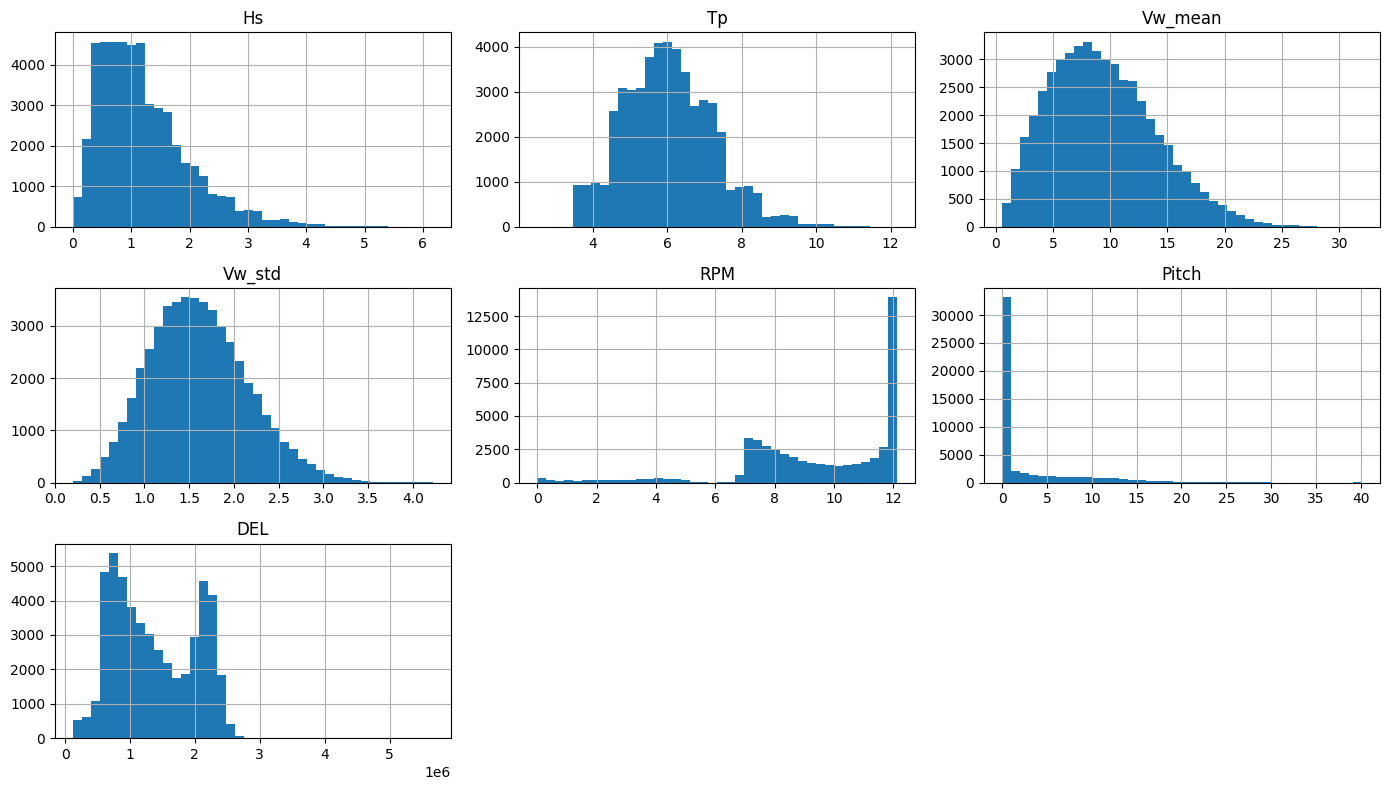

In [6]:
# === Histograms ===

X.hist(bins=40, figsize=(14, 8))
plt.tight_layout()
plt.show()

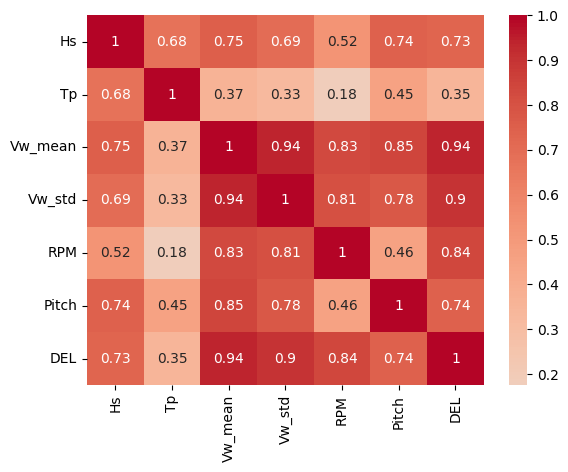

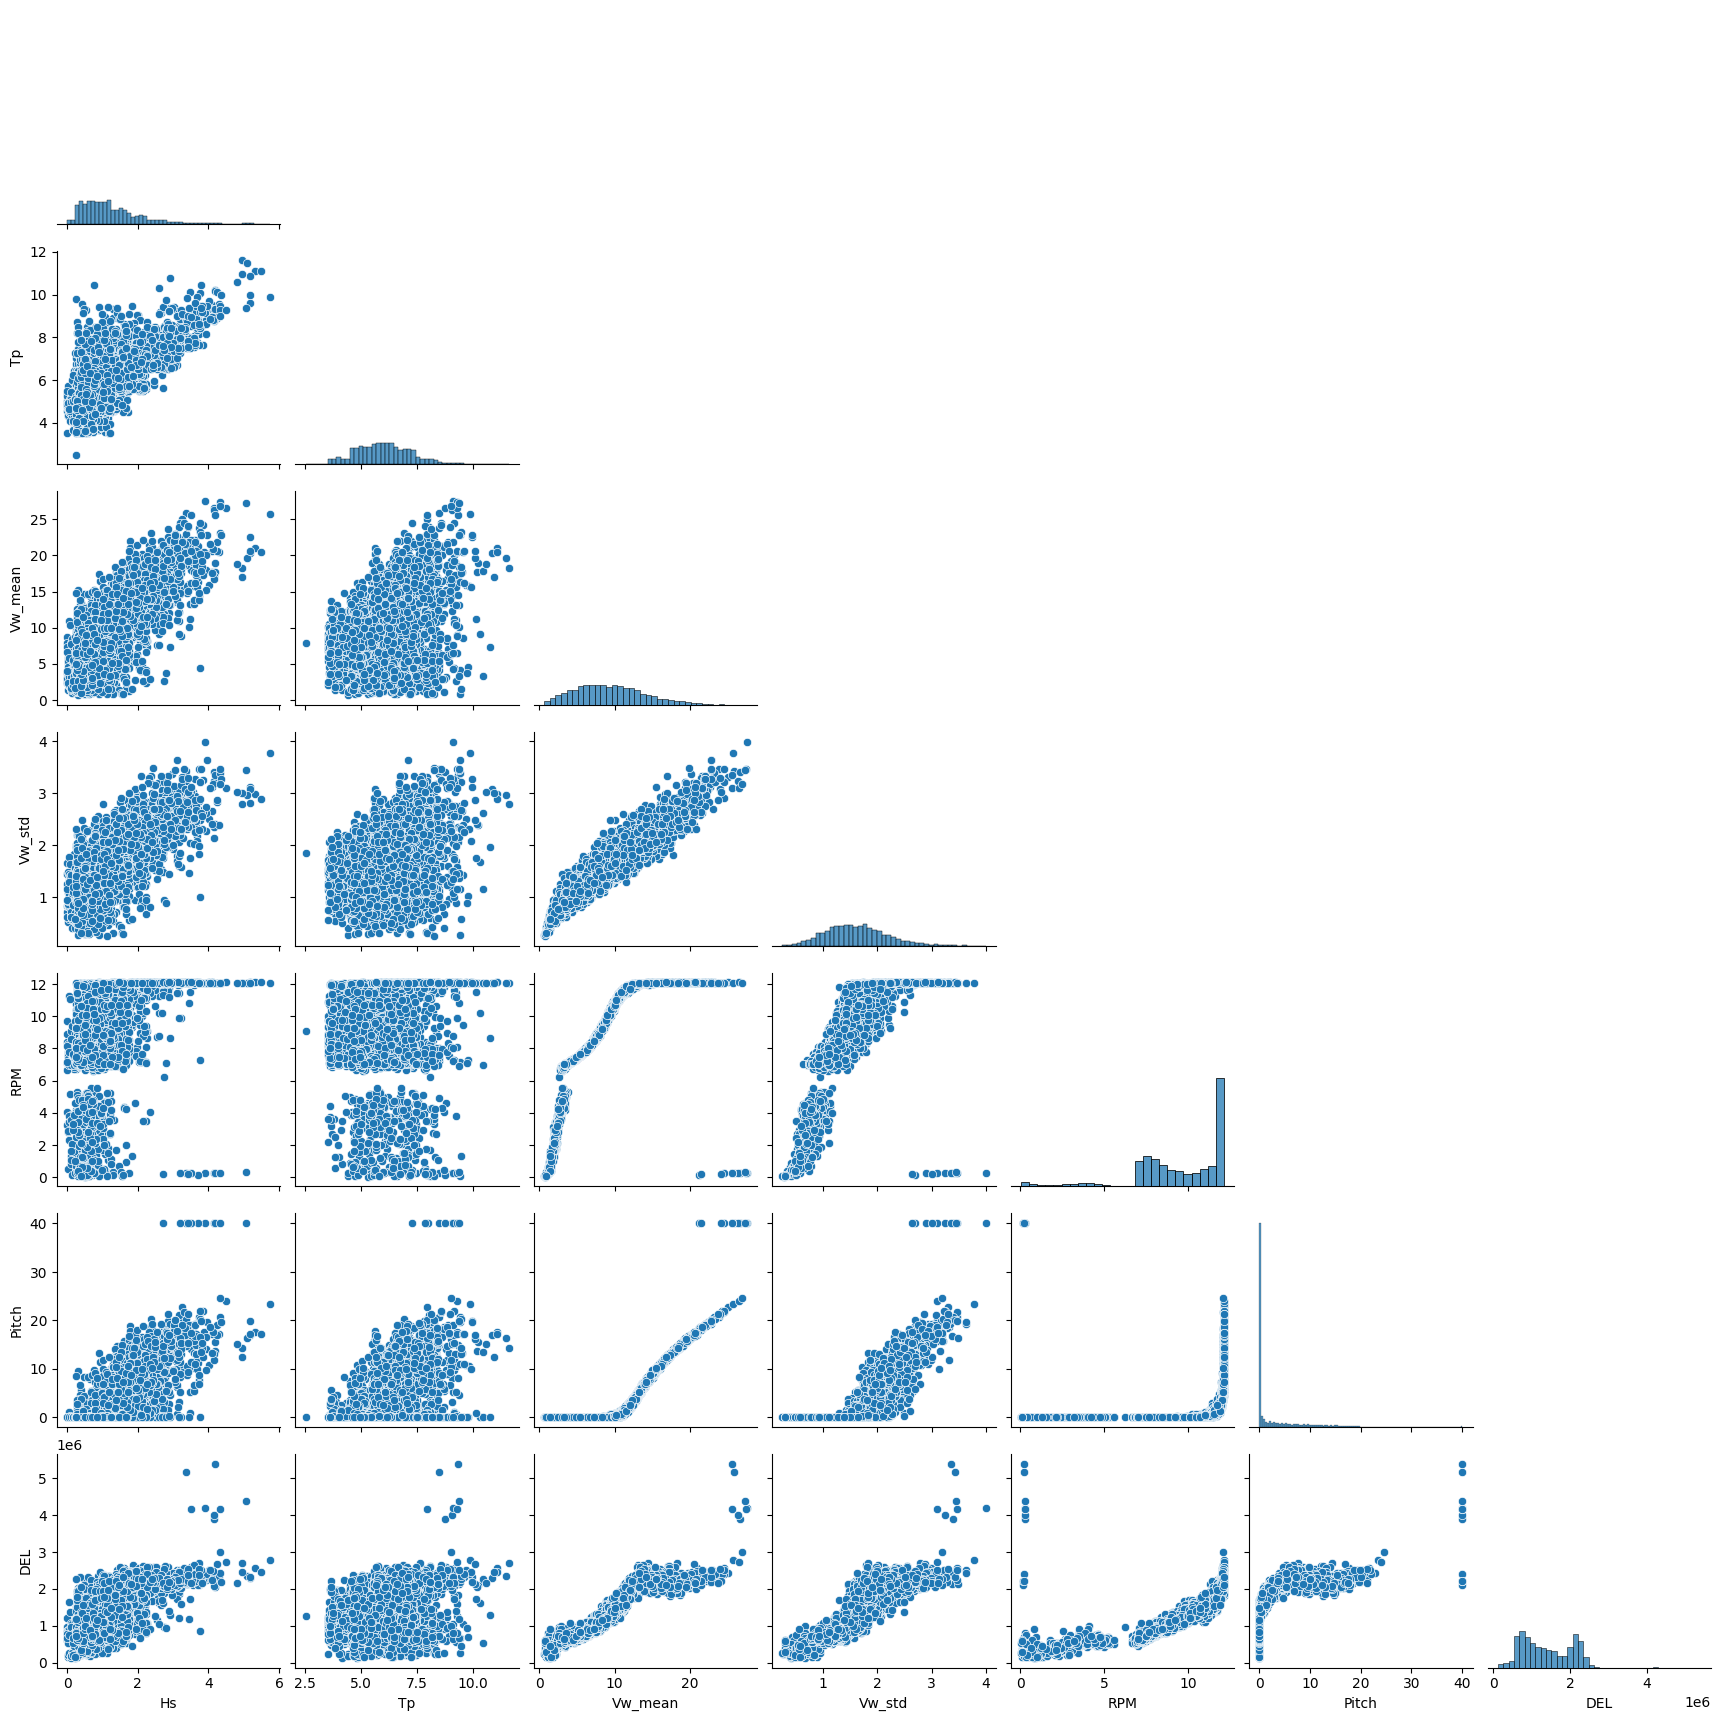

In [7]:
# === COrrelations and joint relationships ===

sns.heatmap(X.corr(), annot=True, cmap="coolwarm", center=0)
plt.show()

sns.pairplot(X.sample(min(5000, len(X))), corner=True)
plt.show()

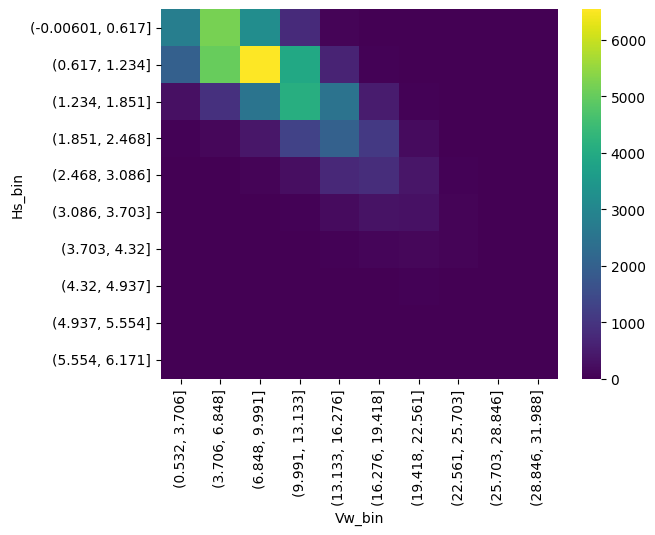

In [8]:
# === Operating/space coverage ===

df["Hs_bin"] = pd.cut(df["Hs"], bins=10)
df["Vw_bin"] = pd.cut(df["Vw_mean"], bins=10)

coverage = pd.crosstab(df["Hs_bin"], df["Vw_bin"])
sns.heatmap(coverage, cmap="viridis")
plt.show()

## Operating Conditions


In [9]:
# === Stats during operating conditions ===

operating = df[
    (df["RPM"] > 0)
    & df["Vw_mean"].between(6, 25)
].copy()

print(f"Operating rows: {len(operating)} / {len(df)} "
      f"({len(operating) / len(df):.1%})")

Operating rows: 36688 / 49791 (73.7%)


In [10]:
# === Operating statistics ===

operating[["Hs", "Tp", "Vw_mean", "Vw_std",
           "RPM", "Pitch", "DEL"]].describe().T

operating["Vw_bin"] = pd.cut(
    operating["Vw_mean"],
    bins=np.arange(0, operating["Vw_mean"].max() + 1, 1),
)

coverage = operating.groupby("Vw_bin", observed=True).agg(
    count=("DEL", "size"),
    mean_DEL=("DEL", "mean"),
    std_DEL=("DEL", "std"),
)
print(coverage)

              count      mean_DEL        std_DEL
Vw_bin                                          
(6.0, 7.0]     3968  8.855326e+05   92851.605427
(7.0, 8.0]     4183  1.027895e+06  112817.828151
(8.0, 9.0]     4083  1.183040e+06  127057.555767
(9.0, 10.0]    3852  1.365265e+06  135745.485709
(10.0, 11.0]   3646  1.550266e+06  145540.055008
(11.0, 12.0]   3365  1.836047e+06  155231.338555
(12.0, 13.0]   2993  2.076349e+06  139311.501216
(13.0, 14.0]   2492  2.222171e+06  134541.502151
(14.0, 15.0]   2036  2.254456e+06  136989.993814
(15.0, 16.0]   1555  2.232069e+06  143410.423959
(16.0, 17.0]   1317  2.188783e+06  147842.311501
(17.0, 18.0]    991  2.166497e+06  153670.833500
(18.0, 19.0]    721  2.166427e+06  147358.512518
(19.0, 20.0]    547  2.200828e+06  135708.606647
(20.0, 21.0]    379  2.231721e+06  134417.049414
(21.0, 22.0]    268  2.286937e+06  132735.861054
(22.0, 23.0]    157  2.361054e+06  132287.218111
(23.0, 24.0]     87  2.399370e+06  142194.289786
(24.0, 25.0]     48 

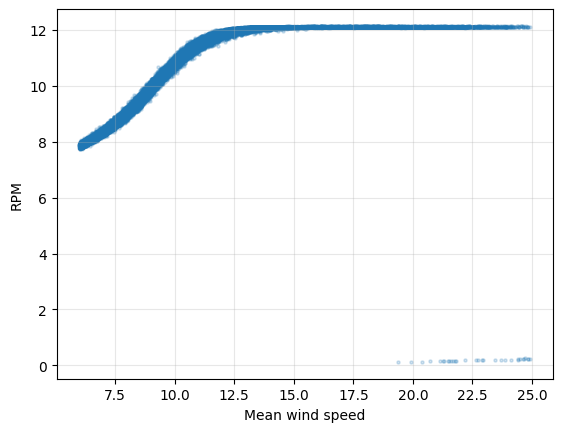

In [ ]:
# === Scatter plot of Vw_mean speed vs RPM ===

plt.scatter(operating["Vw_mean"], operating["RPM"], s=5, alpha=0.2)
plt.xlabel("Mean Vw_mean speed")
plt.ylabel("RPM")
plt.grid(alpha=0.3)
plt.show()

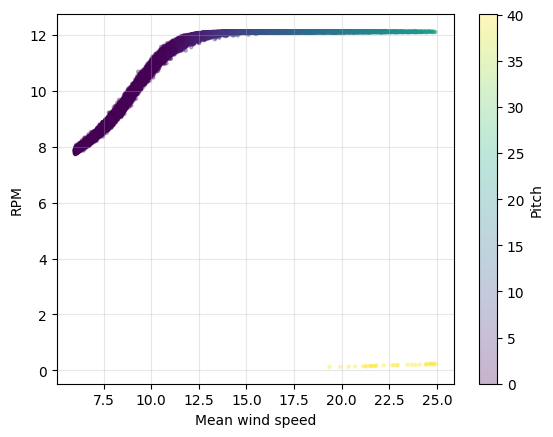

In [12]:
plt.scatter(
    operating["Vw_mean"],
    operating["RPM"],
    c=operating["Pitch"],
    #cmap="viridis",
    s=5,
    alpha=0.3,
)
plt.xlabel("Mean wind speed")
plt.ylabel("RPM")
plt.colorbar(label="Pitch")
plt.grid(alpha=0.3)
plt.show()

In [13]:
states = pd.DataFrame(index=df.index)
states["below_cut_in"] = df["Vw_mean"] < 3.0
states["startup_or_low_rpm"] = (
    (df["RPM"] >= 4.0)
    & (df["RPM"] < 6.9)
)
states["normal_partial_load"] = (
    (df["Vw_mean"] >= 3.0)
    & (df["Vw_mean"] < 11.4)
    & (df["RPM"] >= 6.9)
)
states["rated_operation"] = (
    (df["Vw_mean"] >= 11.4)
    & (df["Vw_mean"] < 25.0)
)
states["cutout_or_shutdown"] = df["Vw_mean"] >= 25.0

In [14]:
low_rpm = df[df["RPM"].between(4, 6.9)]

print("Low-RPM samples:", len(low_rpm))
print(
    "Fraction of dataset:",
    len(low_rpm) / len(df)
)

print(
    low_rpm[["Vw_mean", "RPM", "Pitch", "DEL"]].describe()
)

Low-RPM samples: 1292
Fraction of dataset: 0.02594846458195256
           Vw_mean          RPM   Pitch           DEL
count  1292.000000  1292.000000  1292.0  1.292000e+03
mean      2.993677     4.993706     0.0  6.059395e+05
std       0.257063     0.934811     0.0  8.792667e+04
min       2.298974     4.000183     0.0  4.177594e+05
25%       2.806097     4.337444     0.0  5.437572e+05
50%       2.984846     4.668784     0.0  5.952382e+05
75%       3.178536     5.170927     0.0  6.517063e+05
max       3.999793     6.899820     0.0  1.044242e+06


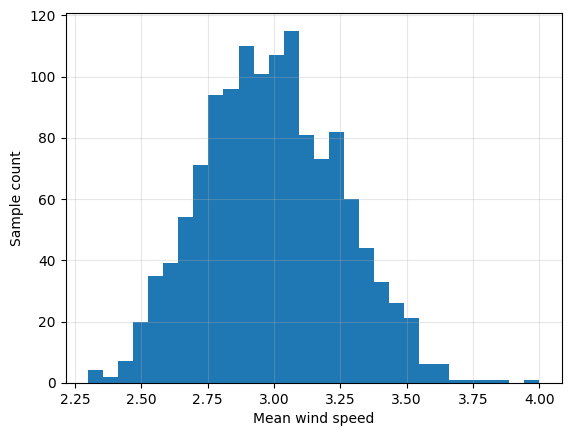

In [15]:
import matplotlib.pyplot as plt

plt.hist(low_rpm["Vw_mean"].dropna(), bins=30)
plt.xlabel("Mean wind speed")
plt.ylabel("Sample count")
plt.grid(alpha=0.3)
plt.show()

## Save the operating conditions info

In [1]:
# NREL 5-MW reference turbine values
RATED_POWER_MW = 5.0
CUT_IN_MS = 3.0
RATED_WIND_MS = 11.4
CUT_OUT_MS = 25.0
MIN_RPM = 6.9
RATED_RPM = 12.1

In [8]:
# Convert to arrays in case these variables are pandas Series
wind = np.asarray(Vw_mean)
rpm = np.asarray(RPM)

df["wind_curve_pct"] = np.nan

below_cut_in = wind < CUT_IN_MS
partial_load = (wind >= CUT_IN_MS) & (wind < RATED_WIND_MS)
rated_region = (wind >= RATED_WIND_MS) & (wind < CUT_OUT_MS)

df.loc[below_cut_in, "wind_curve_pct"] = 0

df.loc[partial_load, "wind_curve_pct"] = (
    100 * (wind[partial_load]**3 - CUT_IN_MS**3)
    / (RATED_WIND_MS**3 - CUT_IN_MS**3)
)

df.loc[rated_region, "wind_curve_pct"] = 100

conditions = [
    wind < CUT_IN_MS,
    wind >= CUT_OUT_MS,
    (wind >= CUT_IN_MS) & (wind < CUT_OUT_MS) & (rpm < MIN_RPM),
    (wind >= CUT_IN_MS) & (wind < CUT_OUT_MS) & (rpm >= MIN_RPM),
]
labels = [
    "Below cut-in",
    "At/above cut-out",
    "Low RPM: startup, shutdown, or check",
    "Normal RPM range",
]
df["operating_state"] = np.select(
    conditions, labels, default="Check data"
)

normal_running = (
    (wind >= CUT_IN_MS)
    & (wind < CUT_OUT_MS)
    & (rpm >= MIN_RPM)
    & (rpm <= RATED_RPM + 0.5)
)

df["estimated_pct_rated"] = np.where(
    normal_running,
    df["wind_curve_pct"],
    np.nan,
)
df["estimated_power_MW"] = (
    df["estimated_pct_rated"] / 100 * RATED_POWER_MW
)

print(df["operating_state"].value_counts(dropna=False))

operating_state
Normal RPM range                        45786
Below cut-in                             3232
Low RPM: startup, shutdown, or check      669
At/above cut-out                          104
Name: count, dtype: int64


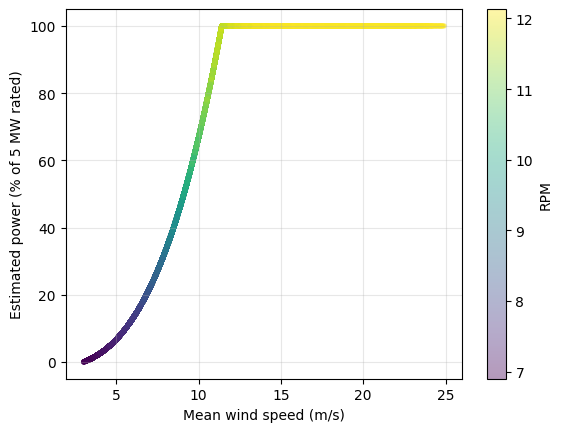

In [9]:
plt.scatter(
    df["Vw_mean"],
    df["estimated_pct_rated"],
    c=df["RPM"],
    cmap="viridis",
    s=8,
    alpha=0.4,
)
plt.xlabel("Mean wind speed (m/s)")
plt.ylabel("Estimated power (% of 5 MW rated)")
plt.colorbar(label="RPM")
plt.grid(alpha=0.3)
plt.show()

In [10]:
state_codes = {
    "Normal RPM range": 0,
    "Below cut-in": 1,
    "Low RPM: startup, shutdown, or check": 2,
    "At/above cut-out": 3,
}

unmapped = set(df["operating_state"].dropna().unique()) - set(state_codes)
if unmapped:
    raise ValueError(f"Unexpected operating-state labels: {unmapped}")

df["operating_state"] = df["operating_state"].map(state_codes).astype("Int64")

columns_to_save = [
    "Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch", "DEL",
    "operating_state",
]
df[columns_to_save].to_csv("NREL_DEL.csv", index=False)